## GRUPO 8 – DETECÇÃO DE FRAUDE EM CARTÃO DE CRÉDITO
- Alunos: Alberto, Geovane, Gustavo

Contexto do Projeto: Prever fraude em cartão de crédito Como cientista de dados o seu principal objetivo neste projeto é construir um modelo de aprendizado de máquina capaz de detectar se uma transação com cartão de crédito é normal ou fraudulenta. O conjunto de dados contém transações feitas com cartões de crédito em setembro de 2013 por titulares de cartões europeus. Este conjunto de dados apresenta transações que ocorreram em dois dias, onde tivemos 492 fraudes em 284.807 transações. Dados do projeto:
https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud?select=creditcard.csv

## Estágio 1 – Compreendendo o negócio



### Descrição do Negócio (Compreensão)
O projeto foca na análise de fraudes em transações com cartões de crédito realizadas na MegaLoja SA, uma grande varejista que atua em operações online e físicas, oferecendo uma ampla variedade de produtos. Devido ao alto volume de transações, a empresa enfrenta desafios com fraudes financeiras, que geram perdas financeiras e prejudicam a confiança dos clientes. A MegaLoja SA estima que a taxa de fraude esteja próxima de 0,2%, tornando essencial o entendimento desse cenário e a busca por possíveis padrões.

### Objetivos do Negócio
Realizar uma *análise descritiva detalhada* das transações com cartões de crédito da empresa para entender melhor o comportamento das fraudes, investigando padrões, tendências e fatores que contribuem para falsos positivos e negativos. Este trabalho tem como propósito fornecer insights para melhorar a segurança e assertividade futura no combate a fraudes.

### *Definição do Problema*

A MegaLoja SA precisa compreender melhor o comportamento das transações fraudulentas em um cenário altamente desbalanceado, no qual apenas uma pequena porcentagem das transações é fraude (aproximadamente 0,2%). O problema está em identificar padrões e características que diferem fraudes de transações legítimas, além de investigar erros como falsos positivos, que podem frustrar clientes, e falsos negativos, que geram perdas financeiras diretas.

### *Formalização das Hipóteses*

1. As fraudes possuem padrões distintos em relação a variáveis como horário, valor e frequência das transações.
2. Falsos positivos acontecem, geralmente, em transações legítimas consideradas atípicas.
3. Falsos negativos surgem em casos onde fraudes simulam comportamentos normais de clientes.
4. A análise descritiva permitirá identificar variáveis-chave e comportamentos que diferenciam as fraudes das transações legítimas.

### *Estratégias de Solução*

1. *Analisar o dataset de forma descritiva*, identificando proporções, padrões e características dos dados gerais e das fraudes.
2. *Visualizar os dados* por meio de gráficos e análises para identificar comportamentos e padrões importantes.
3. *Investigar falsos positivos e negativos*, examinando as variáveis associadas a cada tipo de erro.
4. *Gerar insights detalhados* e documentar as principais descobertas para utilização em estratégias futuras de mitigação de fraudes.

### *Plano do Projeto*

1. *Compreender os objetivos e contexto*: Detalhar os problemas e hipóteses iniciais do trabalho.
2. *Explorar os dados*: Realizar uma análise exploratória inicial para identificar padrões gerais e o desbalanceamento entre fraudes e transações legítimas.
3. *Analisar fraudes e erros*: Focar na análise descritiva das variáveis principais e investigar os padrões associados às fraudes, falsos positivos e negativos.
4. *Documentar os resultados*: Consolidar as análises em um relatório final com descobertas, limitações e recomendações futuras.

slide: https://www.canva.com/design/DAGyiS1GSck/vKdKS4MxCG1VoI9zPC0L0w/edit

## Estágio 2 - ENTENDER OS DADOS
- visão geral dos dados
- Coleta de dados iniciais
- Descrever dados
- Explorar Dados
- Verificar qualidade dos dados

link slide:https://canva.link/x44226u0l5czn2f

**Tarefas: considere os seguintes questionamentos**

- Quais atributos (colunas) do banco de dados parecem mais promissores?

R: As colunas mais promissoras destacadas são: V1; V2; V3; TIME; AMOUNT; CLASS   

- Quais atributos parecem irrelevantes e podem ser excluídos?

R: neste primeiro momento, as colunas da V9 A V28, pois o modelo de padronização PCA por padrão as primeiras colunas possuem mais informações.

- Há dados suficientes para tirar conclusões generalizáveis ou fazer previsões precisas?

R: Neste primeiro momento, não é possivel tirar conclusões generalizáveis ou fazer previsões precisas.

- Há muitos atributos para o seu método de modelagem de escolha?

R: Sim, pelo fato do modelo de padronização PCA.

- Você está mesclando várias fontes de dados?

R: Não, apenas o data set inicial.

- Você considerou como os valores ausentes são tratados em cada uma das suas fontes de dados?

R: Não, pois não a dados ausente

In [ ]:
# Bibliotecas
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA, TruncatedSVD
import matplotlib.patches as mpatches
import time

# Classifier Libraries
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import collections


# Other Libraries
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from imblearn.pipeline import make_pipeline as imbalanced_make_pipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import NearMiss
from imblearn.metrics import classification_report_imbalanced
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, accuracy_score, classification_report
from collections import Counter
from sklearn.model_selection import KFold, StratifiedKFold
import warnings
warnings.filterwarnings("ignore")

In [ ]:
db = pd.read_csv('/content/creditcard.csv')

db.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0.0
1,0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0.0
2,1,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0.0
3,1,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0.0
4,2,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0.0


In [ ]:
db.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,37722.000000,37722.000000,37722.000000,37722.000000,37722.000000,37722.000000,37722.000000,37721.000000,37721.000000,37721.000000,...,37721.000000,37721.000000,37721.000000,37721.000000,37721.000000,37721.000000,37721.000000,37721.000000,37721.000000,37721.000000
mean,24766.905519,-0.207438,0.060003,0.717371,0.192425,-0.223913,0.099322,-0.113878,0.036184,0.234569,...,-0.030242,-0.112267,-0.041283,0.006498,0.136187,0.021816,0.009257,0.003928,86.029572,0.002731
std,12527.587139,1.826290,1.542122,1.518753,1.404199,1.379541,1.306858,1.250118,1.229029,1.230965,...,0.760639,0.639297,0.550248,0.593787,0.435848,0.505541,0.386284,0.299030,232.994577,0.052184
min,0.000000,-30.552380,-40.978852,-31.103685,-5.172595,-42.147898,-23.496714,-26.548144,-41.484823,-7.175097,...,-20.262054,-8.593642,-26.751119,-2.836627,-7.495741,-1.438650,-8.567638,-9.617915,0.000000,0.000000
25%,13890.000000,-0.962070,-0.514064,0.239253,-0.715389,-0.827569,-0.639691,-0.595964,-0.154250,-0.543033,...,-0.238364,-0.535135,-0.178672,-0.327777,-0.127541,-0.331097,-0.063228,-0.007002,7.190000,0.000000
50%,29826.000000,-0.231670,0.107303,0.822135,0.188408,-0.262141,-0.159274,-0.073638,0.045764,0.108784,...,-0.079107,-0.085964,-0.052248,0.061264,0.176033,-0.064077,0.008660,0.021275,22.820000,0.000000
75%,34937.750000,1.161603,0.748540,1.451850,1.073459,0.300384,0.486727,0.434617,0.310800,0.960733,...,0.098007,0.298240,0.076458,0.398894,0.421271,0.301099,0.085603,0.075752,77.750000,0.000000
max,39077.000000,1.960497,16.713389,4.101716,13.143668,34.099309,22.529298,36.677268,20.007208,10.392889,...,22.614889,5.805795,17.297845,4.014444,5.525093,3.517346,11.135740,5.678671,7879.420000,1.000000


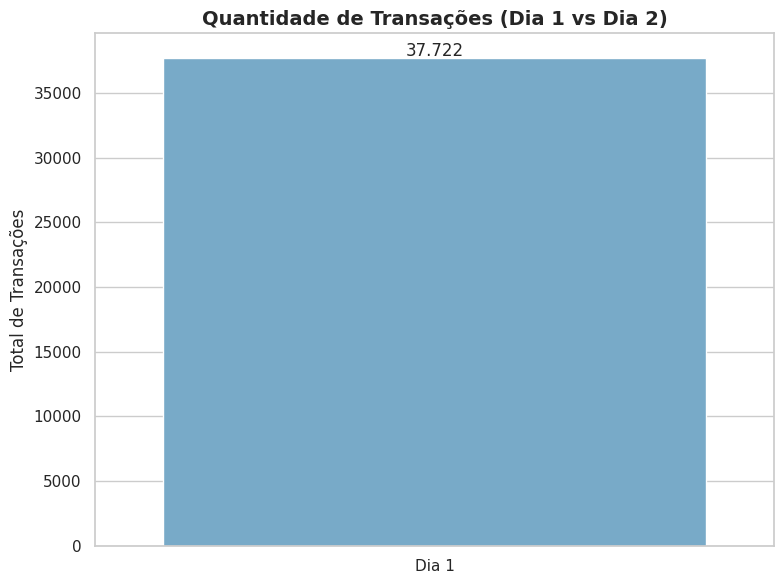

In [ ]:
# GRAFICO DE QUANTIDADE DE TRANSAÇÕES NOS 2 DIAS
# Configurando o estilo visual dos gráficos
sns.set_theme(style="whitegrid")

# Criando a coluna 'Dia' com a regra dos 86400 segundos
db['Dia'] = db['Time'].apply(lambda x: 'Dia 1' if x <= 86400 else 'Dia 2')

# Gerando o Gráfico 1
plt.figure(figsize=(8, 6))
ax1 = sns.countplot(data=db, x='Dia', palette='Blues')
plt.title('Quantidade de Transações (Dia 1 vs Dia 2)', fontsize=14, fontweight='bold')
plt.ylabel('Total de Transações')
plt.xlabel('')

# Adicionando os rótulos numéricos nas barras
for p in ax1.patches:
    texto_formatado = f'{int(p.get_height()):,}'.replace(',', '.')
    ax1.annotate(texto_formatado, (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

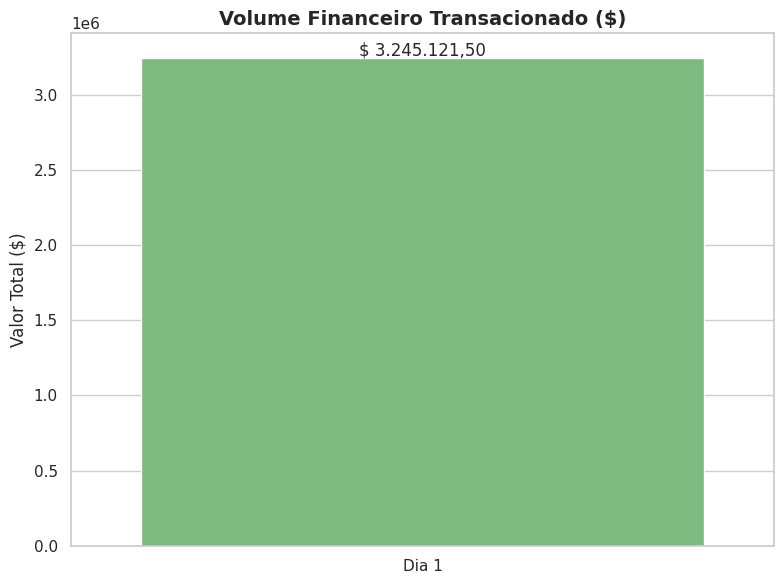

In [ ]:
# GRÁFICO DE VALOR TOTAL EM DIAS
plt.figure(figsize=(8, 6))

# Agrupando a soma do valor (Amount) por dia
valor_por_dia = db.groupby('Dia')['Amount'].sum().reset_index()

ax2 = sns.barplot(data=valor_por_dia, x='Dia', y='Amount', palette='Greens')
plt.title('Volume Financeiro Transacionado ($)', fontsize=14, fontweight='bold')
plt.ylabel('Valor Total ($)')
plt.xlabel('')

# Adicionando os rótulos de dados formatados como moeda
for p in ax2.patches:
    valor = p.get_height()
    texto_us = f'{valor:,.2f}'
    texto_br = texto_us.replace(',', 'X').replace('.', ',').replace('X', '.')
    ax2.annotate(f'$ {texto_br}', (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

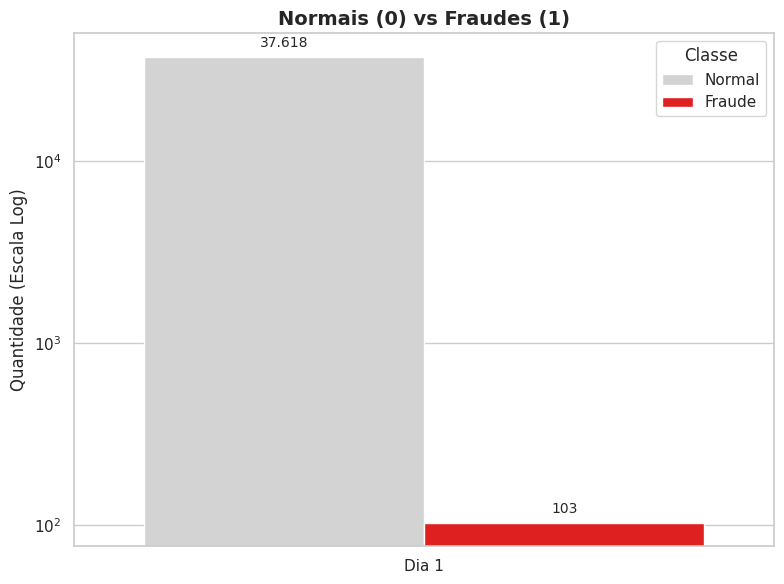

In [ ]:
# GRÁFICO DE FRAUDES EM 2 DIAS
plt.figure(figsize=(8, 6))

# Plotando com separação por Classe (0 = Normal, 1 = Fraude)
ax3 = sns.countplot(data=db, x='Dia', hue='Class', palette={0: 'lightgrey', 1: 'red'})
plt.title('Normais (0) vs Fraudes (1)', fontsize=14, fontweight='bold')
plt.yscale('log') # Escala logarítmica para evidenciar a diferença extrema
plt.ylabel('Quantidade (Escala Log)')
plt.xlabel('')

# Adicionando os rótulos numéricos nas barras (Padrão Brasileiro)
for p in ax3.patches:
    altura = p.get_height()
    # Verifica se a barra tem algum valor para não dar erro em barras vazias
    if altura > 0:
        texto_formatado = f'{int(altura):,}'.replace(',', '.')
        ax3.annotate(texto_formatado,
                     (p.get_x() + p.get_width() / 2., altura),
                     ha='center', va='bottom', # Usando 'bottom' para ficar certinho em cima da barra
                     xytext=(0, 5), textcoords='offset points',
                     fontsize=10)

# Ajustando a legenda
plt.legend(title='Classe', labels=['Normal', 'Fraude'])

plt.tight_layout()
plt.show()

In [ ]:
# Since our classes are highly skewed we should make them equivalent in order to have a normal distribution of the classes.

# Lets shuffle the data before creating the subsamples

df = pd.read_csv('/content/creditcard.csv')
df = df.sample(frac=1)

# amount of fraud classes 492 rows.
fraud_df = df.loc[df['Class'] == 1]
non_fraud_df = df.loc[df['Class'] == 0][:492]

normal_distributed_df = pd.concat([fraud_df, non_fraud_df])

# Shuffle dataframe rows
new_df = normal_distributed_df.sample(frac=1, random_state=42)

new_df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
46988,43022,1.174407,-0.237578,0.585989,0.794385,-0.910939,-0.714316,-0.259939,0.037571,0.926596,...,-0.316211,-0.928336,0.088425,0.347267,0.219529,0.291984,-0.044983,0.014706,33.35,0.0
18061,29156,-1.232071,0.550349,2.706389,1.075413,1.159165,1.816155,0.781223,0.243067,-0.688598,...,-0.067681,0.143466,0.134319,-1.031081,-0.115009,-0.213173,-0.316604,-0.424510,44.61,0.0
28912,35230,1.287679,-0.758803,1.092531,-0.524910,-1.709607,-0.906167,-0.979646,-0.089197,-0.412381,...,0.422001,1.093267,-0.089935,0.767156,0.369021,-0.073191,0.031194,0.034841,44.99,0.0
15286,26659,1.231022,0.103880,0.368654,0.440370,-0.353621,-0.499664,-0.109241,0.017962,-0.042132,...,-0.236188,-0.776973,0.090682,-0.034497,0.196453,0.100597,-0.040684,0.004152,6.48,0.0
47575,43261,1.457700,-1.521865,-0.770513,-2.442675,0.590473,3.524320,-1.830660,0.862305,-1.678638,...,-0.028195,0.095654,-0.110094,1.009297,0.514817,-0.036920,0.049574,0.029129,59.99,0.0


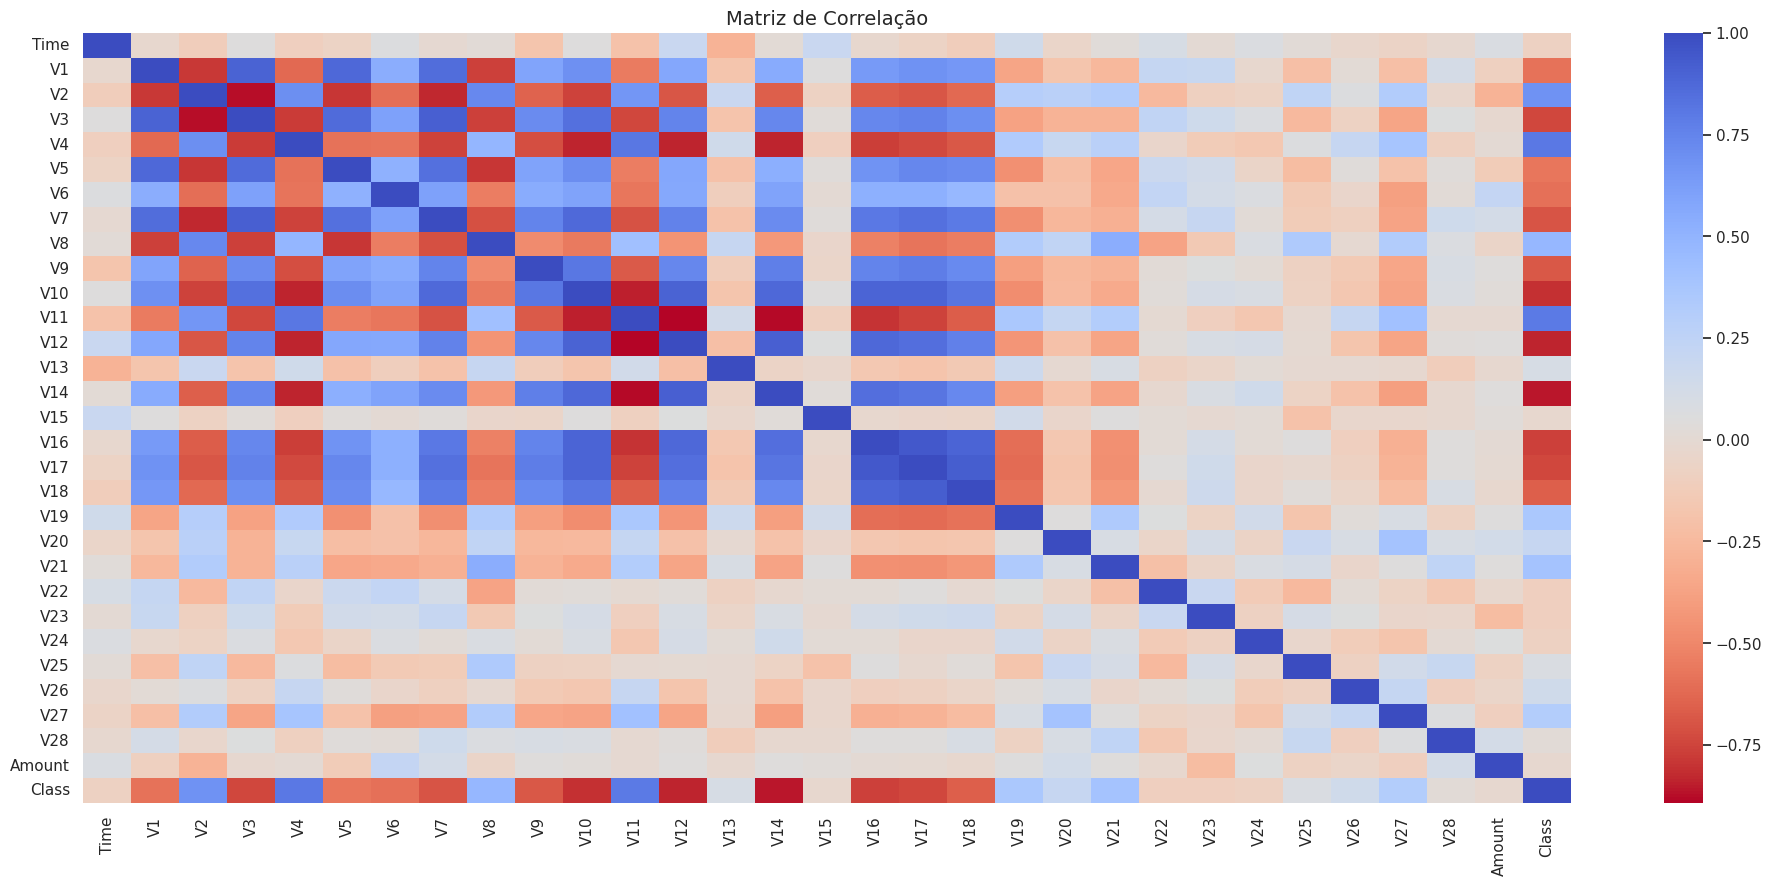

In [ ]:
# Definindo o tamanho da figura para uma única matriz
plt.figure(figsize=(24, 10))

# Calculando a correlação apenas do sub_sample
sub_sample_corr = new_df.corr()

# Gerando o heatmap
sns.heatmap(sub_sample_corr, cmap='coolwarm_r', annot_kws={'size':20})

# Configurando o título
plt.title('Matriz de Correlação', fontsize=14)

plt.show()

##Estágio 3: Preparação dos dados
- Dados a partir daqui, serão modificados

Link slide: https://canva.link/0mpu4b9st4wykqi

AÇÕES:

1. Limpar e selecionar os dados que interessam, contruir novos dados e formatar dados
  - Tratamento de Outliers na coluna Amount
  - Normalização/Escalonamento na coluna Amount (min - max)
  - Quais colunas entre v1 a v28 tem relação direta com a coluna Class
  - Selecionar uma amostra balanciada para o treinamento e testes
  - Criar a coluna horas


In [ ]:
%pip install pandas matplotlib seaborn sklearn

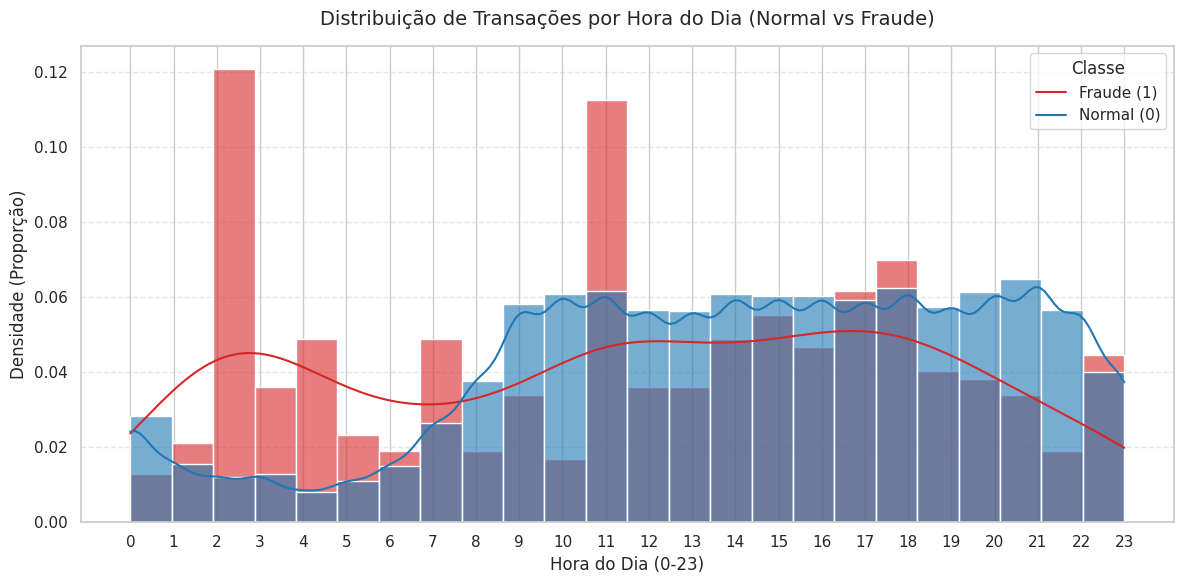

In [ ]:
# CRIAR A COLUNA HORAS
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/creditcard.csv')

# 1. TRANSFORMAÇÃO: Converte os segundos em horas (de 0 a 23)
df['Hour'] = (df['Time'] / 3600).astype(int) % 24

# 2. VISUALIZAÇÃO: Cria o gráfico para comparar as classes
plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x='Hour',
    hue='Class',        # Separa as cores por Normal (0) e Fraude (1)
    bins=24,            # Uma barra para cada hora do dia
    kde=True,           # Adiciona a linha de tendência suave
    stat='density',     # Normaliza os dados (proporção)
    common_norm=False,  # Calcula a densidade de fraudes e normais separadamente
    palette={0: '#1f77b4', 1: '#d62728'}, # Azul para Normal, Vermelho para Fraude
    alpha=0.6
)

# Configurações de título e eixos
plt.title('Distribuição de Transações por Hora do Dia (Normal vs Fraude)', fontsize=14, pad=15)
plt.xlabel('Hora do Dia (0-23)', fontsize=12)
plt.ylabel('Densidade (Proporção)', fontsize=12)
plt.xticks(range(0, 24))
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Ajusta a legenda e exibe o gráfico
plt.legend(title='Classe', labels=['Fraude (1)', 'Normal (0)'])
plt.tight_layout()
plt.show()

In [ ]:
# VERFICIAÇÃO DE OUTLIERS
import pandas as pd

# 1. Calcula o Q1 (25%) e o Q3 (75%) da coluna Amount
Q1 = df['Amount'].quantile(0.25)
Q3 = df['Amount'].quantile(0.75)

# 2. Calcula o IQR (o "miolo" dos dados)
IQR = Q3 - Q1

# 3. Define o Limite Superior de normalidade (Regra clássica do Boxplot)
limite_superior = Q3 + 1.5 * IQR

# 4. Filtra o DataFrame apenas para as linhas onde o Amount ultrapassa o limite
df_outliers = df[df['Amount'] > limite_superior]

# RESULTADOS
print(f"O limite matemático para transações normais é: R$ {limite_superior:.2f}")
print(f"Total de outliers encontrados: {len(df_outliers)} transações")
print(f"Isso representa {(len(df_outliers) / len(df)) * 100:.2f}% do dataset.\n")

# Mostra as 10 transações mais absurdas (do maior para o menor valor)
print("Top 10 maiores transações (Outliers Absolutos):")
print(df_outliers[['Hour', 'Amount', 'Class']].sort_values(by='Amount', ascending=False).head(10))

O limite matemático para transações normais é: R$ 184.51
Total de outliers encontrados: 31904 transações
Isso representa 11.20% do dataset.

Top 10 maiores transações (Outliers Absolutos):
        Hour    Amount  Class
274771    22  25691.16      0
58465     13  19656.53      0
151296     2  18910.00      0
46841     11  12910.93      0
54018     12  11898.09      0
169457     9  11789.84      0
284249    23  10199.44      0
227921    16  10000.00      0
74699     15   8790.26      0
245474    18   8787.00      0


In [ ]:
# NORMALIZAÇÃO OU ESCALONAMENTO DA COLUNA AMOUNT

# Importa o escalonador do Scikit-Learn
from sklearn.preprocessing import RobustScaler

# 1. Inicializa o escalonador (o "motor" matemático)
rob_scaler = RobustScaler()

# 2. Aplica a transformação na coluna Amount
# Usamos [['Amount']] com dois colchetes para que o Pandas envie os dados no formato 2D que o Scikit-Learn exige
df['Scaled_Amount'] = rob_scaler.fit_transform(df[['Amount']])

# 3. Exclui a coluna original, pois ela não serve mais e causaria ruído no modelo
df = df.drop(['Amount'], axis=1)

# 4. (Opcional) Mostra as primeiras linhas para você validar a mudança
print(df[['Scaled_Amount', 'Class']].head(10))

   Scaled_Amount  Class
0       1.783274      0
1      -0.269825      0
2       4.983721      0
3       1.418291      0
4       0.670579      0
5      -0.256131      0
6      -0.237686      0
7       0.262698      0
8       0.994900      0
9      -0.255991      0


In [ ]:
# COLUNAS V1 A V28 RELEVANTES: Calculando a correlação com a coluna 'Class'

# Seleciona as colunas V1 a V28 e a coluna Class
columns_to_correlate = ['V' + str(i) for i in range(1, 29)] + ['Class']
correlation_df = df[columns_to_correlate]

# Calcula a correlação com a coluna 'Class'
correlations_with_class = correlation_df.corr()['Class'].drop('Class')

# Exibe as correlações em ordem decrescente do valor absoluto para identificar as mais fortes
print("Correlação das colunas V com a coluna 'Class' (ordenada por valor absoluto):\n")
print(correlations_with_class.abs().sort_values(ascending=False))

Correlação das colunas V com a coluna 'Class' (ordenada por valor absoluto):

V17    0.326481
V14    0.302544
V12    0.260593
V10    0.216883
V16    0.196539
V3     0.192961
V7     0.187257
V11    0.154876
V4     0.133447
V18    0.111485
V1     0.101347
V9     0.097733
V5     0.094974
V2     0.091289
V6     0.043643
V21    0.040413
V19    0.034783
V20    0.020090
V8     0.019875
V27    0.017580
V28    0.009536
V24    0.007221
V13    0.004570
V26    0.004455
V15    0.004223
V25    0.003308
V23    0.002685
V22    0.000805
Name: Class, dtype: float64


#### Hold-out

In [ ]:
# 1. SEPARAÇÃO INICIAL (80% Treino / 20% Teste)
from sklearn.model_selection import train_test_split
from imblearn.under_sampling import RandomUnderSampler

# Separa os dados garantindo a proporção original no primeiro momento
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 2. CONFIGURAÇÃO DO MOTOR DE BALANCEAMENTO
# O RandomUnderSampler vai reduzir a classe majoritária (0) até o limite da classe minoritária (1)
rus = RandomUnderSampler(random_state=42)

# 3. APLICAÇÃO EXCLUSIVA NO TREINO (Protegendo a base de teste)
X_train_bal, y_train_bal = rus.fit_resample(X_train, y_train)

# 4. VALIDAÇÃO OPERACIONAL DA FASE 3
print("--- STATUS DO BALANCEAMENTO ---")
print("\nVolume do Treino Original (Com viés):")
print(y_train.value_counts())

print("\nVolume do Treino Balanceado (Matriz limpa para o Modelo):")
print(y_train_bal.value_counts())

print("\nVolume do Teste (Intacto / Fotografia do Mundo Real):")
print(y_test.value_counts())

--- STATUS DO BALANCEAMENTO ---

Volume do Treino Original (Com viés):
Class
0.0    394
1.0    118
Name: count, dtype: int64

Volume do Treino Balanceado (Matriz limpa para o Modelo):
Class
0.0    118
1.0    118
Name: count, dtype: int64

Volume do Teste (Intacto / Fotografia do Mundo Real):
Class
0.0    98
1.0    30
Name: count, dtype: int64


##Estágio 5: Aplicação dos modelos
Link slide: https://canva.link/239nl4zm3h6dj2s

Modelos:
- XGBoost
- One-Class SVM
- Isolation Forest

#### XGBoost

In [ ]:
# 1. IMPORTAÇÃO DAS FERRAMENTAS
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# 2. CONFIGURAÇÃO DO MOTOR XGBOOST
modelo_xgb = XGBClassifier(
    objective='binary:logistic',
    eval_metric='auc',
    max_depth=4,
    learning_rate=0.1,
    random_state=42
)

# 3. TREINAMENTO (ATUALIZADO PARA A BASE BALANCEADA)
print("Iniciando treinamento do XGBoost na matriz balanceada (50/50)...")
# ATENÇÃO: Variáveis atualizadas nesta linha
modelo_xgb.fit(X_train_bal, y_train_bal)
print("Treinamento concluído.")

# 4. PREVISÃO E VALIDAÇÃO DE RESULTADOS (BASE DE TESTE INTACTA)
previsoes = modelo_xgb.predict(X_test)
probabilidades = modelo_xgb.predict_proba(X_test)[:, 1]

print("\n--- RESULTADOS OPERACIONAIS ---")
print("\nMatriz de Confusão:")
print(confusion_matrix(y_test, previsoes))

print("\nRelatório de Classificação:")
print(classification_report(y_test, previsoes))

print(f"\nROC-AUC Score: {roc_auc_score(y_test, probabilidades):.4f}")

Iniciando treinamento do XGBoost na matriz balanceada (50/50)...
Treinamento concluído.

--- RESULTADOS OPERACIONAIS ---

Matriz de Confusão:
[[96  2]
 [ 3 27]]

Relatório de Classificação:
              precision    recall  f1-score   support

         0.0       0.97      0.98      0.97        98
         1.0       0.93      0.90      0.92        30

    accuracy                           0.96       128
   macro avg       0.95      0.94      0.94       128
weighted avg       0.96      0.96      0.96       128


ROC-AUC Score: 0.9959


#### One-Class SVM

In [ ]:
# One-Class SVM
# 1. IMPORTAÇÃO DAS FERRAMENTAS
from sklearn.svm import OneClassSVM
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# 2. FILTRAGEM (A MÁGICA DA DETECÇÃO DE ANOMALIA)
# Isolamos APENAS as transações normais (Classe 0) da base de treino ORIGINAL
X_train_normal = X_train[y_train == 0]

# 3. CONFIGURAÇÃO DO MOTOR ONE-CLASS SVM
# nu=0.01 indica uma margem rígida assumindo que fraudes são uma minoria extrema
modelo_ocsvm = OneClassSVM(kernel='rbf', gamma='scale', nu=0.01)

# 4. TREINAMENTO
print("Iniciando treinamento do OCSVM exclusivamente com o padrão 'Normal'...")
modelo_ocsvm.fit(X_train_normal)
print("Treinamento concluído.")

# 5. PREVISÃO NA BASE DE TESTE (INTACTA)
previsoes_brutas = modelo_ocsvm.predict(X_test)

# 6. TRADUÇÃO DAS SAÍDAS PARA O NOSSO PADRÃO (0 = Normal, 1 = Fraude)
# O OCSVM retorna -1 para anomalias. Vamos converter isso para 1 (Nossa Classe de Fraude)
# E o que ele retornar como 1 (Normal), vamos converter para 0
previsoes_ajustadas = np.where(previsoes_brutas == -1, 1, 0)

# 7. VALIDAÇÃO OPERACIONAL
print("\n--- RESULTADOS OPERACIONAIS ---")
print("\nMatriz de Confusão:")
print(confusion_matrix(y_test, previsoes_ajustadas))

print("\nRelatório de Classificação:")
print(classification_report(y_test, previsoes_ajustadas))

Iniciando treinamento do OCSVM exclusivamente com o padrão 'Normal'...
Treinamento concluído.

--- RESULTADOS OPERACIONAIS ---

Matriz de Confusão:
[[97  1]
 [29  1]]

Relatório de Classificação:
              precision    recall  f1-score   support

         0.0       0.77      0.99      0.87        98
         1.0       0.50      0.03      0.06        30

    accuracy                           0.77       128
   macro avg       0.63      0.51      0.46       128
weighted avg       0.71      0.77      0.68       128



#### Isolation Forest

In [ ]:
# Isolation Forest
# 1. IMPORTAÇÃO DAS FERRAMENTAS
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# 2. CONFIGURAÇÃO DO MOTOR ISOLATION FOREST
# contamination=0.01 define o teto estatístico de anomalias esperadas na base
modelo_if = IsolationForest(
    n_estimators=100,
    max_samples='auto',
    contamination=0.01,
    random_state=42
)

# 3. TREINAMENTO
print("Iniciando treinamento da Isolation Forest na base ORIGINAL (desbalanceada)...")
# ATENÇÃO: Usando X_train puro, a floresta precisa do palheiro inteiro para achar a agulha
modelo_if.fit(X_train)
print("Treinamento concluído.")

# 4. PREVISÃO NA BASE DE TESTE (INTACTA)
previsoes_brutas_if = modelo_if.predict(X_test)

# 5. TRADUÇÃO DAS SAÍDAS PARA O NOSSO PADRÃO (0 = Normal, 1 = Fraude)
# A floresta retorna -1 para anomalias. Vamos converter para 1.
previsoes_if_ajustadas = np.where(previsoes_brutas_if == -1, 1, 0)

# 6. VALIDAÇÃO OPERACIONAL
print("\n--- RESULTADOS OPERACIONAIS ---")
print("\nMatriz de Confusão:")
print(confusion_matrix(y_test, previsoes_if_ajustadas))

print("\nRelatório de Classificação:")
print(classification_report(y_test, previsoes_if_ajustadas))

Iniciando treinamento da Isolation Forest na base ORIGINAL (desbalanceada)...
Treinamento concluído.

--- RESULTADOS OPERACIONAIS ---

Matriz de Confusão:
[[98  0]
 [30  0]]

Relatório de Classificação:
              precision    recall  f1-score   support

         0.0       0.77      1.00      0.87        98
         1.0       0.00      0.00      0.00        30

    accuracy                           0.77       128
   macro avg       0.38      0.50      0.43       128
weighted avg       0.59      0.77      0.66       128



## Estágio 5.1 – Ensable learning

1. Treinar os Modelos:
- SVM
- KNN
- REGRAÇÃO LÓGISCA

2. Avaliar acurácia: em validação cruzada
3. Criar um ensemble de Voting (soft)
4. Comparar com os modelos das etapas anteriores.

link dos slides: https://canva.link/0degrqmyx2qhtz9

#### Regreção lógistica

In [ ]:
# REGRAÇÃO LÓGISCA

import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression

# ATENÇÃO: Use o Pipeline do imblearn, NÃO do sklearn!
# Ele é preparado para lidar com balanceamento dentro do K-Fold
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler

df = pd.read_csv('creditcard.csv')

# 2. REMOVER DADOS NULOS: Remove qualquer linha que tenha valores NaN
df = df.dropna()

# 3. Separar X e y com os dados limpos
X = df.drop('Class', axis=1)
y = df['Class']

# 2. Configurar a Validação Cruzada Estratificada (5 divisões)
# Mantém a proporção de 0.17% de fraudes em cada dobra
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 3. Construir o Pipeline à prova de vazamentos
# Cada passo aqui só será aplicado aos dados de TREINO de cada dobra
pipeline_lr = Pipeline(steps=[
    ('scaler', RobustScaler()), # Trata o peso dos outliers sem apagá-los
    ('sampler', RandomUnderSampler(random_state=42)), # Balanceia as classes reduzindo a classe majoritária
    ('modelo', LogisticRegression(max_iter=1000, random_state=42)) # O modelo em si
])

# 4. Métricas de Avaliação
# Para dados desbalanceados, a acurácia é inútil. Usamos Recall, Precision e F1.
metricas = ['accuracy', 'precision', 'recall', 'f1']

# 5. Executar a Validação Cruzada
print("Iniciando Validação Cruzada (isso pode demorar alguns minutos)...")
resultados = cross_validate(
    estimator=pipeline_lr,
    X=X,
    y=y,
    cv=skf,
    scoring=metricas,
    n_jobs=-1 # Usa todos os núcleos do seu processador
)

# 6. Exibir os resultados médios de validação
print(f"Média Precision: {resultados['test_precision'].mean():.4f}")
print(f"Média Recall (Detecção de Fraudes): {resultados['test_recall'].mean():.4f}")
print(f"Média F1-Score: {resultados['test_f1'].mean():.4f}")

Iniciando Validação Cruzada (isso pode demorar alguns minutos)...
Média Precision: 0.0488
Média Recall (Detecção de Fraudes): 0.9166
Média F1-Score: 0.0926


#### SVM

In [ ]:
# SVM

import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import RobustScaler
from sklearn.svm import SVC
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler

# 1. Carregamento e limpeza (conforme resolvemos no passo anterior)
# Se você já tem X e y carregados e limpos na memória, pode pular esta parte.
df = pd.read_csv('creditcard.csv')
df = df.dropna()
X = df.drop('Class', axis=1)
y = df['Class']

# 2. Configurar a Validação Cruzada Estratificada (5 divisões)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 3. Construir o Pipeline com o SVM
# O SVC usará o kernel 'rbf' por padrão, que é ótimo para relações não-lineares
pipeline_svm = Pipeline(steps=[
    ('scaler', RobustScaler()),
    ('sampler', RandomUnderSampler(random_state=42)),
    ('modelo', SVC(random_state=42)) # Aqui entra o SVM
])

# 4. Métricas de Avaliação
metricas = ['accuracy', 'precision', 'recall', 'f1']

# 5. Executar a Validação Cruzada
print("Iniciando Validação Cruzada com SVM (prepare um café, isso vai demorar um pouco)...")
resultados_svm = cross_validate(
    estimator=pipeline_svm,
    X=X,
    y=y,
    cv=skf,
    scoring=metricas,
    n_jobs=-1 # Extremamente importante deixar em -1 para usar todos os núcleos do processador
)

# 6. Exibir os resultados médios
print(f"Média Precision: {resultados_svm['test_precision'].mean():.4f}")
print(f"Média Recall (Detecção de Fraudes): {resultados_svm['test_recall'].mean():.4f}")
print(f"Média F1-Score: {resultados_svm['test_f1'].mean():.4f}")

Iniciando Validação Cruzada com SVM (prepare um café, isso vai demorar um pouco)...
Média Precision: 0.0746
Média Recall (Detecção de Fraudes): 0.8679
Média F1-Score: 0.1371


##### Métricas iguais ao Hold-out

In [ ]:
# SVM COM AS MESMAS MÉTRICAS DO SVM (HOLD-OUT)
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.preprocessing import RobustScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler

# 1. CARREGAMENTO E PREPARAÇÃO DOS DADOS
print("Carregando o dataset creditcard.csv...")
df = pd.read_csv('creditcard.csv')

# Removendo possíveis valores nulos para evitar erros
df = df.dropna()

# Separando as variáveis (X = características da transação, y = fraude ou não)
X = df.drop('Class', axis=1)
y = df['Class']
print(f"Dataset carregado com sucesso! Total de linhas: {len(df)}")

# 2. CONFIGURAÇÃO DA VALIDAÇÃO CRUZADA E DO PIPELINE SEGURO
# Mantém a proporção de fraudes em todas as 5 dobras
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Pipeline que escala, balanceia e aplica o SVM apenas nos dados de treino de cada dobra
pipeline_svm = Pipeline(steps=[
    ('scaler', RobustScaler()),
    ('sampler', RandomUnderSampler(random_state=42)),
    ('modelo', SVC(random_state=42))
])

# 3. GERAÇÃO DAS PREVISÕES VIA VALIDAÇÃO CRUZADA
print("\nIniciando previsões com SVM Supervisionado via Validação Cruzada...")
print("(Pegue aquele café, pois o SVM avaliará as 5 dobras. Isso pode levar alguns minutos.)")

# cross_val_predict gera a previsão para cada linha do dataset quando ela era 'teste'
previsoes_cv = cross_val_predict(
    estimator=pipeline_svm,
    X=X,
    y=y,
    cv=skf,
    n_jobs=-1 # Usa todos os núcleos do processador para ir mais rápido
)

# 4. EXIBIÇÃO DOS RESULTADOS COMPARATIVOS
print("\n--- RESULTADOS OPERACIONAIS (SVM SUPERVISIONADO - CV) ---")

print("\nMatriz de Confusão:")
print(confusion_matrix(y, previsoes_cv))

print("\nRelatório de Classificação:")
print(classification_report(y, previsoes_cv))

Carregando o dataset creditcard.csv...
Dataset carregado com sucesso! Total de linhas: 284807

Iniciando previsões com SVM Supervisionado via Validação Cruzada...
(Pegue aquele café, pois o SVM avaliará as 5 dobras. Isso pode levar alguns minutos.)

--- RESULTADOS OPERACIONAIS (SVM SUPERVISIONADO - CV) ---

Matriz de Confusão:
[[278837   5478]
 [    65    427]]

Relatório de Classificação:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99    284315
           1       0.07      0.87      0.13       492

    accuracy                           0.98    284807
   macro avg       0.54      0.92      0.56    284807
weighted avg       1.00      0.98      0.99    284807



#### KNN

In [ ]:
# KNN
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import RobustScaler
from sklearn.neighbors import KNeighborsClassifier
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler

# 1. Carregamento e limpeza (caso precise rodar do zero)
df = pd.read_csv('creditcard.csv')
df = df.dropna()
X = df.drop('Class', axis=1)
y = df['Class']

# 2. Configurar a Validação Cruzada Estratificada
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 3. Construir o Pipeline com o KNN
pipeline_knn = Pipeline(steps=[
    ('scaler', RobustScaler()),
    ('sampler', RandomUnderSampler(random_state=42)),
    ('modelo', KNeighborsClassifier(n_neighbors=5)) # KNN padrão com 5 vizinhos
])

# 4. Métricas de Avaliação
metricas = ['accuracy', 'precision', 'recall', 'f1']

# 5. Executar a Validação Cruzada
print("Iniciando Validação Cruzada com KNN...")
resultados_knn = cross_validate(
    estimator=pipeline_knn,
    X=X,
    y=y,
    cv=skf,
    scoring=metricas,
    n_jobs=-1
)

# 6. Exibir os resultados médios
print(f"Média Precision: {resultados_knn['test_precision'].mean():.4f}")
print(f"Média Recall (Detecção de Fraudes): {resultados_knn['test_recall'].mean():.4f}")
print(f"Média F1-Score: {resultados_knn['test_f1'].mean():.4f}")

Iniciando Validação Cruzada com KNN...
Média Precision: 0.0433
Média Recall (Detecção de Fraudes): 0.8881
Média F1-Score: 0.0825


##**Estágio 5.2**



```
O que fazer:
- BAGGING (validação cruzada)
de cada modelo individual
- BOOSTING (validação cruzada)
Xgboots e mais um
- STACKING (validação cruzada)
KNN, RL, SVM,
- ALINHADO (Boostrap)
STACKING, BAGGIN, 1 BOOST (META MODELO)

ALINHADO DOS VENCEDORES
```
Para slides:
- Apresentar os resultados
- fazer um comparativo com os modelos anteriores

Link slides:https://docs.google.com/presentation/d/1xhK8elPqdSPBhHI3vyNAhWqwkVQFs39UxuDV-87UHTw/edit?usp=sharing

###VOTING CLASSIFIER

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# 1. Carregamento dos dados
X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.1, random_state=42, stratify=y
)

# 2. Definição dos estimadores base
# Dica: SVC precisa de probability=True para ser usado com voting='soft'
clf1 = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
clf2 = RandomForestClassifier(n_estimators=100, random_state=42)
clf3 = make_pipeline(StandardScaler(), SVC(probability=True, random_state=42))

# 3. Configuração do VotingClassifier
# Use voting='soft' (pondera pelas probabilidades previstas) ou 'hard' (votação por maioria simples)
ensemble = VotingClassifier(
    estimators=[
        ('lr', clf1),
        ('rf', clf2),
        ('svc', clf3)
    ],
    voting='soft',
    weights=[1, 2, 1]  # Opcional: pesos atribuídos a cada modelo
)

# 4. Treinamento
ensemble.fit(X_train, y_train)

# 5. Avaliação
y_pred = ensemble.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.91      0.95      0.93        21
           1       0.97      0.94      0.96        36

    accuracy                           0.95        57
   macro avg       0.94      0.95      0.94        57
weighted avg       0.95      0.95      0.95        57



### BAGGING

In [ ]:
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import BaggingClassifier
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler

# 1. Carregamento e separação dos dados (assumindo a base já limpa)
df = pd.read_csv('creditcard.csv').dropna()
X = df.drop('Class', axis=1)
y = df['Class']

# 2. Configuração da Validação Cruzada Estratificada
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 3. Construção dos Pipelines Base seguros contra vazamento de dados
pipe_lr = Pipeline([
    ('scaler', RobustScaler()),
    ('sampler', RandomUnderSampler(random_state=42)),
    ('lr', LogisticRegression(max_iter=1000, random_state=42))
])

pipe_knn = Pipeline([
    ('scaler', RobustScaler()),
    ('sampler', RandomUnderSampler(random_state=42)),
    ('knn', KNeighborsClassifier(n_neighbors=5))
])

pipe_svm = Pipeline([
    ('scaler', RobustScaler()),
    ('sampler', RandomUnderSampler(random_state=42)),
    ('svm', SVC(probability=True, random_state=42)) # probability=True ajuda caso precisemos para Voting depois
])

# 4. Envolvendo os Pipelines no BaggingClassifier
# n_estimators=10 cria 10 versões diferentes do modelo base
bagging_lr = BaggingClassifier(estimator=pipe_lr, n_estimators=10, random_state=42, n_jobs=-1)
bagging_knn = BaggingClassifier(estimator=pipe_knn, n_estimators=10, random_state=42, n_jobs=-1)
bagging_svm = BaggingClassifier(estimator=pipe_svm, n_estimators=10, random_state=42, n_jobs=-1)

# 5. Dicionário para iterar e avaliar os modelos
modelos_bagging = {
    'Bagging - Regressão Logística': bagging_lr,
    'Bagging - KNN': bagging_knn,
    'Bagging - SVM': bagging_svm
}

metricas = ['accuracy', 'precision', 'recall', 'f1']

# 6. Execução da Validação Cruzada para cada modelo Bagging
print("Iniciando treinamento Bagging com Validação Cruzada...\n")

for nome, modelo in modelos_bagging.items():
    print(f"Avaliando {nome}...")
    resultados = cross_validate(
        estimator=modelo,
        X=X,
        y=y,
        cv=skf,
        scoring=metricas,
        n_jobs=-1
    )

    print(f"Média Precision: {resultados['test_precision'].mean():.4f}")
    print(f"Média Recall: {resultados['test_recall'].mean():.4f}")
    print(f"Média F1-Score: {resultados['test_f1'].mean():.4f}\n")
    print("-" * 40 + "\n")

Iniciando treinamento Bagging com Validação Cruzada...

Avaliando Bagging - Regressão Logística...
Média Precision: 0.0567
Média Recall: 0.9146
Média F1-Score: 0.1068

----------------------------------------

Avaliando Bagging - KNN...
Média Precision: 0.0549
Média Recall: 0.8882
Média F1-Score: 0.1034

----------------------------------------

Avaliando Bagging - SVM...
Média Precision: 0.0480
Média Recall: 0.9004
Média F1-Score: 0.0911

----------------------------------------



### BOOSTING

In [ ]:
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import AdaBoostClassifier
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler

# 1. Preparação dos dados limpos
df = pd.read_csv('creditcard.csv').dropna()
X = df.drop('Class', axis=1)
y = df['Class']

# 2. Configuração da Validação Cruzada Estratificada
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metricas = ['precision', 'recall', 'f1']

# 3. Dicionário com os Motores de Boosting
# O XGBoost mantém a configuração da etapa 5, enquanto o AdaBoost usará 100 iterações (estimators)
modelos_boosting = {
    'XGBoost': XGBClassifier(
        objective='binary:logistic',
        eval_metric='auc',
        max_depth=4,
        learning_rate=0.1,
        random_state=42
    ),
    'AdaBoost': AdaBoostClassifier(
        n_estimators=100,
        random_state=42
    )
}

# 4. Execução Iterativa: Boosting + Pipeline + Cross Validation
for nome, modelo in modelos_boosting.items():
    print(f"\n--- Iniciando Boosting com {nome} ---")

    # Construindo o Pipeline à prova de vazamentos
    pipeline = Pipeline(steps=[
        ('scaler', RobustScaler()),
        ('sampler', RandomUnderSampler(random_state=42)),
        ('boosting', modelo)
    ])

    # Executando a Validação Cruzada
    resultados = cross_validate(
        estimator=pipeline,
        X=X,
        y=y,
        cv=skf,
        scoring=metricas,
        n_jobs=-1
    )

    # Exibindo os resultados médios de validação
    print(f"Média Precision: {resultados['test_precision'].mean():.4f}")
    print(f"Média Recall (Detecção de Fraudes): {resultados['test_recall'].mean():.4f}")
    print(f"Média F1-Score: {resultados['test_f1'].mean():.4f}")


--- Iniciando Boosting com XGBoost ---
Média Precision: 0.0449
Média Recall (Detecção de Fraudes): 0.9086
Média F1-Score: 0.0855

--- Iniciando Boosting com AdaBoost ---
Média Precision: 0.0346
Média Recall (Detecção de Fraudes): 0.9207
Média F1-Score: 0.0667


### STACKING

In [ ]:
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import StackingClassifier
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler

# 1. Preparação dos dados limpos
df = pd.read_csv('creditcard.csv').dropna()
X = df.drop('Class', axis=1)
y = df['Class']

# 2. Configuração da Validação Cruzada Estratificada (Externa)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metricas = ['precision', 'recall', 'f1']

# 3. Construção do Stacking Classifier
estimadores_base = [
    ('knn', KNeighborsClassifier(n_neighbors=5)),
    ('lr', LogisticRegression(max_iter=1000, random_state=42)),
    ('svm', SVC(random_state=42))
]

# O Stacking usa os modelos base para gerar previsões e um meta-modelo (Regressão Logística) para a decisão final
modelo_stacking = StackingClassifier(
    estimators=estimadores_base,
    final_estimator=LogisticRegression(max_iter=1000, random_state=42),
    cv=5, # Validação cruzada interna para treinar o meta-modelo
    n_jobs=-1
)

# 4. Construção do Pipeline (Garante que o balanceamento ocorra ANTES do Stacking)
pipeline_stacking = Pipeline(steps=[
    ('scaler', RobustScaler()),
    ('sampler', RandomUnderSampler(random_state=42)),
    ('stacking', modelo_stacking)
])

# 5. Execução da Validação Cruzada
print("Iniciando Validação Cruzada com Stacking (Isso exige alto processamento!)...")
resultados_stacking = cross_validate(
    estimator=pipeline_stacking,
    X=X,
    y=y,
    cv=skf,
    scoring=metricas,
    n_jobs=-1
)

# 6. Resultados Operacionais
print(f"Média Precision: {resultados_stacking['test_precision'].mean():.4f}")
print(f"Média Recall (Detecção de Fraudes): {resultados_stacking['test_recall'].mean():.4f}")
print(f"Média F1-Score: {resultados_stacking['test_f1'].mean():.4f}")

Iniciando Validação Cruzada com Stacking (Isso exige alto processamento!)...
Média Precision: 0.0470
Média Recall (Detecção de Fraudes): 0.9024
Média F1-Score: 0.0892


### ALINHADO (VENCEDORES)

In [ ]:
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier, StackingClassifier
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler

# 1. Preparação dos dados limpos
df = pd.read_csv('creditcard.csv').dropna()
X = df.drop('Class', axis=1)
y = df['Class']

# 2. Configuração da Validação Cruzada Estratificada
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metricas = ['precision', 'recall', 'f1']

# ==========================================
# FASE 1: CONSTRUÇÃO DOS MODELOS VENCEDORES
# ==========================================

# Vencedor 1: Bagging com Regressão Logística
bagging_model = BaggingClassifier(
    estimator=LogisticRegression(max_iter=1000, random_state=42),
    n_estimators=10,
    random_state=42
)

# Vencedor 2: Boosting Adaptativo
boosting_model = AdaBoostClassifier(n_estimators=50, random_state=42)

# Vencedor 3: Stacking Clássico (KNN, LR, SVM)
stacking_classico = StackingClassifier(
    estimators=[
        ('knn', KNeighborsClassifier(n_neighbors=5)),
        ('lr', LogisticRegression(max_iter=1000, random_state=42)),
        ('svm', SVC(probability=True, random_state=42))
    ],
    final_estimator=LogisticRegression(max_iter=1000, random_state=42),
    cv=3 # CV interno reduzido para otimizar processamento
)

# ==========================================
# FASE 2: O "ALINHADO" (MEGA-ENSEMBLE)
# ==========================================

# O XGBoost atua como Meta-Modelo recebendo os resultados dos 3 vencedores
mega_ensemble = StackingClassifier(
    estimators=[
        ('bagging', bagging_model),
        ('boosting', boosting_model),
        ('stacking', stacking_classico)
    ],
    final_estimator=XGBClassifier(
        objective='binary:logistic',
        eval_metric='auc',
        max_depth=4,
        learning_rate=0.1,
        random_state=42
    ),
    cv=5,
    n_jobs=-1
)

# 3. Pipeline à Prova de Vazamentos
pipeline_alinhado = Pipeline(steps=[
    ('scaler', RobustScaler()),
    ('sampler', RandomUnderSampler(random_state=42)),
    ('mega_modelo', mega_ensemble)
])

# 4. Execução da Validação Cruzada
print("Iniciando treinamento do Modelo Alinhado...")
resultados_alinhados = cross_validate(
    estimator=pipeline_alinhado,
    X=X,
    y=y,
    cv=skf,
    scoring=metricas,
    n_jobs=-1
)

# 5. Resultados Operacionais
print(f"Média Precision: {resultados_alinhados['test_precision'].mean():.4f}")
print(f"Média Recall (Detecção): {resultados_alinhados['test_recall'].mean():.4f}")
print(f"Média F1-Score: {resultados_alinhados['test_f1'].mean():.4f}")

Iniciando treinamento do Modelo Alinhado...
Média Precision: 0.0395
Média Recall (Detecção): 0.9025
Média F1-Score: 0.0755
